<a href="https://colab.research.google.com/github/Kartikiscalm/IML-LAB-/blob/labs/B25CM1027_Kartik_A3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 1 - Bias-Variance Tradeoff & Decision Tree

In [1]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(2026)
N = 300

hour_of_day = np.sort(rng.uniform(0, 24, N)).round(2)
true_output = 5.2 * np.exp(-((hour_of_day - 13) ** 2) / (2 * 4.5 ** 2))
noise = rng.normal(0, 0.45, N)
output_kwh = np.clip(true_output + noise, 0, None).round(3)

solar_df = pd.DataFrame({
      "hour_of_day": hour_of_day,
      "output_kwh": output_kwh
})

print("Dataset shape:", solar_df.shape)
solar_df.head()

Dataset shape: (300, 2)


,hour_of_day,output_kwh
0,0.04,1.144
1,0.25,0.534
2,0.31,0.175
3,0.31,0.123
4,0.37,0.304


In [2]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

## 1.1 Data Exploration

In [3]:
# Q-1.1

print("First 5 rows:")
display(solar_df.head())

print("\nDataset shape:")
print(solar_df.shape)

print("\nData types:")
print(solar_df.dtypes)

print("\nSummary statistics:")
display(solar_df.describe())

print("\nMissing values:")
print(solar_df.isnull().sum())

First 5 rows:


,hour_of_day,output_kwh
0,0.04,1.144
1,0.25,0.534
2,0.31,0.175
3,0.31,0.123
4,0.37,0.304



Dataset shape:
(300, 2)

Data types:
hour_of_day    float64
output_kwh     float64
dtype: object

Summary statistics:


,hour_of_day,output_kwh
count,300.00000,300.000000
mean,12.21510,2.609950
std,6.68523,1.834691
min,0.04000,0.000000
25%,6.88750,0.795750
50%,12.30000,2.560000
75%,17.74500,4.356250
max,23.99000,6.389000



Missing values:
hour_of_day    0
output_kwh     0
dtype: int64


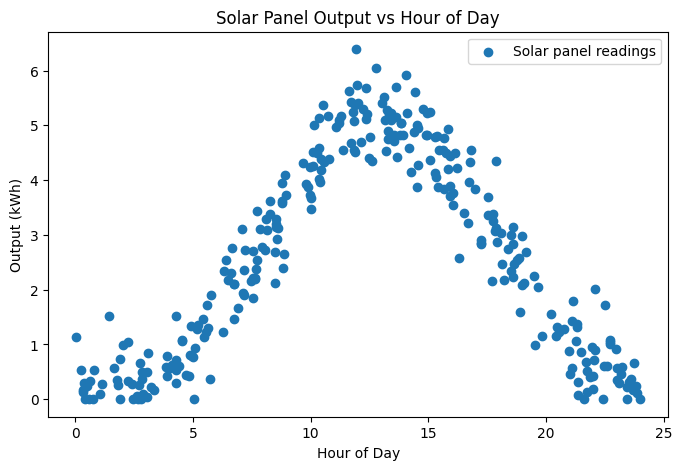

In [4]:
plt.figure(figsize=(8, 5))

plt.scatter(
    solar_df["hour_of_day"],
    solar_df["output_kwh"],
    label="Solar panel readings"
)

plt.title("Solar Panel Output vs Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Output (kWh)")
plt.legend()
plt.show()

In [5]:
X = solar_df[["hour_of_day"]]
y = solar_df["output_kwh"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X shape: (300, 1)
y shape: (300,)
X_train shape: (240, 1)
X_test shape: (60, 1)
y_train shape: (240,)
y_test shape: (60,)


### 1.1 Interpretation

**Bias** is the error that comes from a model being too simple for the true pattern, so it makes systematic mistakes no matter how much data it sees. **Variance** is the error that comes from a model being too sensitive to the particular training sample, so its fitted curve changes a lot if the training data (and its noise) change. The scatter plot shows a smooth bell-shaped pattern: output is close to 0 kWh at night, rises to a peak of about 5-6 kWh around midday, and falls again in the evening, with random noise around this curve. A very simple model (for example a straight line or a single split) cannot follow this rise-and-fall shape and would have high bias, while a very flexible model would start chasing the individual noisy points and would have high variance. So I expect a model of moderate flexibility, one that follows the bell shape without following the noise, to fit this pattern best.

____

## 1.2 Underfitting (Shallow Tree)

In [6]:
# Q-1.2

grid_x = np.linspace(0, 24, 300).reshape(-1, 1)
# same grid wrapped with the feature name the trees were trained with
grid_df = pd.DataFrame(grid_x, columns=["hour_of_day"])

tree_shallow = DecisionTreeRegressor(max_depth=1, random_state=42)
tree_shallow.fit(X_train, y_train)

grid_pred_shallow = tree_shallow.predict(grid_df)
train_pred_shallow = tree_shallow.predict(X_train)
test_pred_shallow = tree_shallow.predict(X_test)

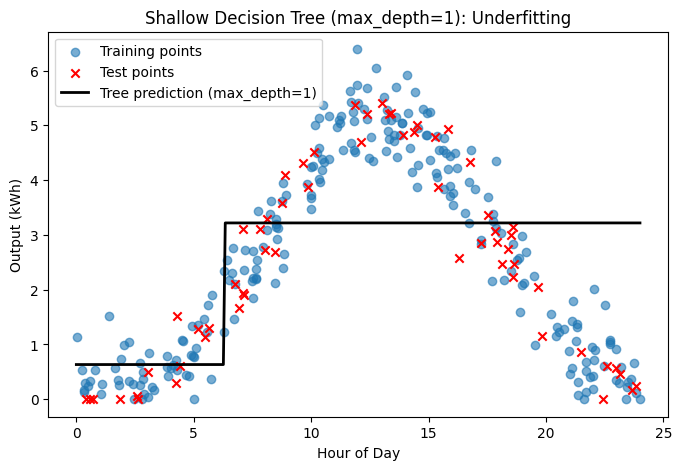

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_train["hour_of_day"],
    y_train,
    alpha=0.6,
    label="Training points"
)

plt.scatter(
    X_test["hour_of_day"],
    y_test,
    marker="x",
    color="red",
    label="Test points"
)

plt.plot(
    grid_x,
    grid_pred_shallow,
    color="black",
    linewidth=2,
    label="Tree prediction (max_depth=1)"
)

plt.title("Shallow Decision Tree (max_depth=1): Underfitting")
plt.xlabel("Hour of Day")
plt.ylabel("Output (kWh)")
plt.legend()
plt.show()

In [8]:
train_mse_shallow = mean_squared_error(y_train, train_pred_shallow)
test_mse_shallow = mean_squared_error(y_test, test_pred_shallow)

print("Shallow tree (max_depth=1)")
print("Training MSE:", train_mse_shallow)
print("Test MSE:", test_mse_shallow)

print("\nNumber of leaves:", tree_shallow.get_n_leaves())
print("Split threshold (hour_of_day):", tree_shallow.tree_.threshold[0])
print("Distinct predicted values over the grid:", len(np.unique(grid_pred_shallow)))

Shallow tree (max_depth=1)
Training MSE: 2.2594155131720433
Test MSE: 1.9923099633888306

Number of leaves: 2
Split threshold (hour_of_day): 6.2900002002716064
Distinct predicted values over the grid: 2


### 1.2 Interpretation

The depth-1 tree makes a single split at about 6.29 hours, so its fitted curve has only two flat levels with one jump between them: about 0.63 kWh before the split and about 3.22 kWh after it. It cannot represent the midday peak or the fall in the evening, so the black line is far from many points on both sides of the peak. The training MSE (2.26) and the test MSE (1.99) are both high and close to each other, which is the signature of **high bias / underfitting**: the model is too simple for the pattern, so its error is large on the training data as well as on unseen data.

____

## 1.3 Overfitting (Deep Tree)

In [9]:
# Q-1.3

tree_deep = DecisionTreeRegressor(random_state=42)
tree_deep.fit(X_train, y_train)

grid_pred_deep = tree_deep.predict(grid_df)
train_pred_deep = tree_deep.predict(X_train)
test_pred_deep = tree_deep.predict(X_test)

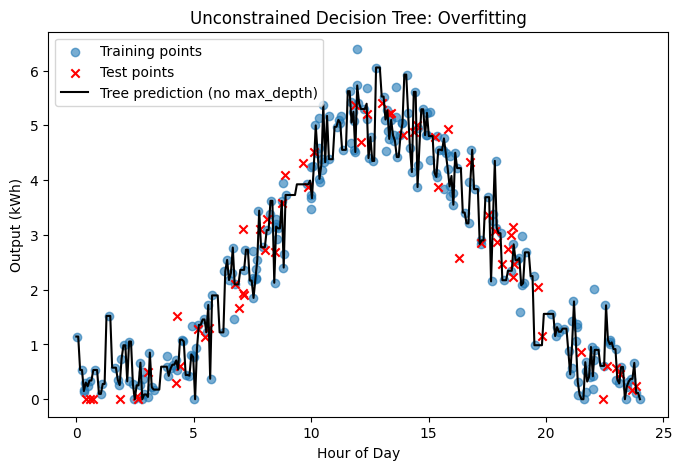

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_train["hour_of_day"],
    y_train,
    alpha=0.6,
    label="Training points"
)

plt.scatter(
    X_test["hour_of_day"],
    y_test,
    marker="x",
    color="red",
    label="Test points"
)

plt.plot(
    grid_x,
    grid_pred_deep,
    color="black",
    linewidth=1.5,
    label="Tree prediction (no max_depth)"
)

plt.title("Unconstrained Decision Tree: Overfitting")
plt.xlabel("Hour of Day")
plt.ylabel("Output (kWh)")
plt.legend()
plt.show()

In [11]:
train_mse_deep = mean_squared_error(y_train, train_pred_deep)
test_mse_deep = mean_squared_error(y_test, test_pred_deep)

print("Unconstrained tree")
print("Tree depth:", tree_deep.get_depth())
print("Number of leaves:", tree_deep.get_n_leaves())
print("Training MSE:", train_mse_deep)
print("Test MSE:", test_mse_deep)

Unconstrained tree
Tree depth: 21
Number of leaves: 223
Training MSE: 0.00977300833333334
Test MSE: 0.31213858749999995


### 1.3 Interpretation

The unconstrained tree grows to a depth of 21 with 223 leaves for only 240 training points, so almost every training point gets its own leaf. Its curve is very jagged and jumps up and down to follow individual noisy points, unlike the two flat levels in Q-1.2. The training MSE is almost zero (0.0098) but the test MSE is 0.312, about 32 times larger, so the tree has memorised the noise in the training sample instead of learning the smooth pattern. This large gap between training and test error is the signature of **high variance / overfitting**.

____

## 1.4 Bias-Variance Sweep Across Depths

In [12]:
# Q-1.4

depths = []
train_mses = []
test_mses = []

for d in range(1, 16):
    tree_d = DecisionTreeRegressor(max_depth=d, random_state=42)
    tree_d.fit(X_train, y_train)

    depths.append(d)
    train_mses.append(mean_squared_error(y_train, tree_d.predict(X_train)))
    test_mses.append(mean_squared_error(y_test, tree_d.predict(X_test)))

depth_error_table = pd.DataFrame({
    "Max_Depth": depths,
    "Train_MSE": train_mses,
    "Test_MSE": test_mses
})

display(depth_error_table)

,Max_Depth,Train_MSE,Test_MSE
0,1,2.259416,1.992310
1,2,0.815670,1.110573
2,3,0.369828,0.495050
3,4,0.228010,0.254910
4,5,0.167667,0.245646
5,6,0.120598,0.251567
6,7,0.089467,0.273112
7,8,0.065250,0.266254
8,9,0.047568,0.272924
9,10,0.032695,0.319425


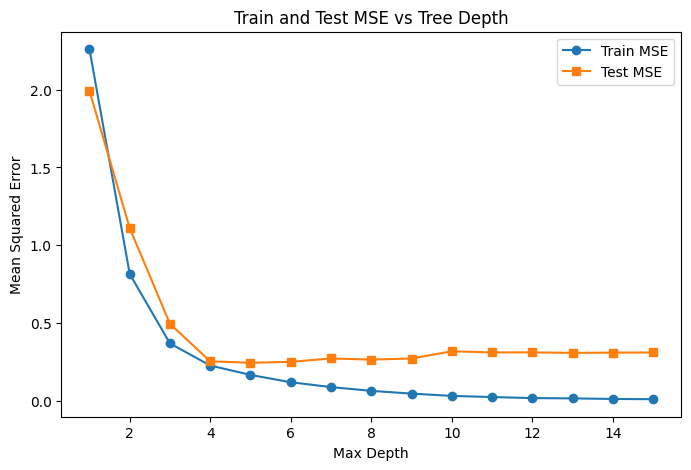

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    depth_error_table["Max_Depth"],
    depth_error_table["Train_MSE"],
    marker="o",
    label="Train MSE"
)

plt.plot(
    depth_error_table["Max_Depth"],
    depth_error_table["Test_MSE"],
    marker="s",
    label="Test MSE"
)

plt.title("Train and Test MSE vs Tree Depth")
plt.xlabel("Max Depth")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.show()

In [14]:
best_row = depth_error_table.loc[depth_error_table["Test_MSE"].idxmin()]
best_depth = int(best_row["Max_Depth"])

print("best_depth:", best_depth)
print("Test MSE at best_depth:", best_row["Test_MSE"])
print("Train MSE at best_depth:", best_row["Train_MSE"])

best_depth: 5
Test MSE at best_depth: 0.24564616716984927
Train MSE at best_depth: 0.1676672129735774


### 1.4 Interpretation

As max_depth increases, the training MSE falls continuously, from 2.26 at depth 1 to 0.012 at depth 15, because a deeper tree can fit the training points more closely. The test MSE drops sharply until depth 4 to 5 (from 1.99 to about 0.25), then stops improving and settles at about 0.31 from depth 10 onwards while the training MSE keeps falling, so a gap opens between the two curves. The computed best_depth is **5** (test MSE 0.246), which sits at the bottom of the test curve: the tree is flexible enough to follow the bell shape but not yet fitting the noise. Depths 4 to 9 give similar test MSE (0.246 to 0.273), so the minimum is fairly flat rather than sharp, and the best test MSE is already close to the noise level of the data (0.45² ≈ 0.20).

____

## Part 1 Final Report

In [15]:
# Q-1.5

final_tree = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
final_tree.fit(X_train, y_train)

final_test_pred = final_tree.predict(X_test)
final_test_mse = mean_squared_error(y_test, final_test_pred)
final_test_rmse = np.sqrt(final_test_mse)

print("Final model: DecisionTreeRegressor(max_depth=best_depth)")
print("best_depth:", best_depth)
print("Final test MSE:", final_test_mse)
print("Final test RMSE:", final_test_rmse)

Final model: DecisionTreeRegressor(max_depth=best_depth)
best_depth: 5
Final test MSE: 0.24564616716984927
Final test RMSE: 0.49562704442942707


As max_depth increased, the training MSE fell steadily from 2.26 to 0.012, while the test MSE dropped sharply until depth 4-5 and then flattened at about 0.31. The lowest test MSE occurred at best_depth = 5, giving a final test MSE of 0.246 (RMSE about 0.496 kWh). The extreme models in Q1.2 and Q1.3 show the two ends of the bias-variance tradeoff: the depth-1 tree has high bias (train MSE 2.26 and test MSE 1.99, both high), while the unconstrained tree has high variance (train MSE 0.010 against test MSE 0.312). One limitation is that best_depth was chosen from a single 60-point test split, so the choice depends on that split, and the final test MSE is slightly optimistic because the same data selected the depth; cross-validation would be more reliable. Pruning, or averaging many trees through bagging, can reduce a tree's variance.

__________________________________________________________

# Part 2 - Ensemble Learning (Bagging & Random Forest)

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

## 2.1 Data Preparation and Single-Tree Baseline

In [17]:
# Q-2.1

print("First 5 rows:")
display(df.head())

print("\nDataset shape:")
print(df.shape)

feature_cols = [col for col in df.columns if col != "target"]

print("\nNumber of feature columns:", len(feature_cols))
print("Total missing values:", df.isnull().sum().sum())

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Dataset shape:
(569, 31)

Number of feature columns: 30
Total missing values: 0


In [18]:
class_counts = df["target"].value_counts().sort_index()
class_percentages = df["target"].value_counts(normalize=True).sort_index() * 100

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})

class_summary = class_summary.rename(index={0: "0 (malignant)", 1: "1 (benign)"})

display(class_summary)

,Count,Percentage
target,,
0 (malignant),212,37.258348
1 (benign),357,62.741652


In [19]:
X = df[feature_cols]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (455, 30)
X_test shape: (114, 30)
y_train shape: (455,)
y_test shape: (114,)


In [20]:
single_tree = DecisionTreeClassifier(random_state=42)
single_tree.fit(X_train, y_train)

tree_train_acc = accuracy_score(y_train, single_tree.predict(X_train))
tree_test_acc = accuracy_score(y_test, single_tree.predict(X_test))

print("Single decision tree (no depth restriction)")
print("Tree depth:", single_tree.get_depth())
print("Number of leaves:", single_tree.get_n_leaves())
print("Training accuracy:", tree_train_acc)
print("Test accuracy:", tree_test_acc)

Single decision tree (no depth restriction)
Tree depth: 7
Number of leaves: 19
Training accuracy: 1.0
Test accuracy: 0.9122807017543859


### 2.1 Interpretation

**Feature matrix (X):** X contains the 30 numeric tumour measurements (the mean, standard error and worst value of radius, texture, perimeter, area, smoothness and so on).

**Target (y):** y is the diagnosis label, where 0 = malignant and 1 = benign.

The 30 features are the independent/input variables, while the target is the dependent/output variable, so this is a binary classification problem.

**Class balance:** The classes are not perfectly balanced (37.3% malignant and 62.7% benign), but the smaller class is still large, and the stratified split keeps these proportions in both the training and test sets.

**Why a single tree is high-variance:** The unconstrained tree reaches 100% training accuracy but only 91.2% test accuracy, the same pattern as the deep tree in Part 1 (train MSE 0.010 against test MSE 0.312): it fits the training sample very closely, so its splits change a lot if the training data change slightly. Averaging many such trees, each trained on a different bootstrap sample, should keep their low bias but let their individual errors cancel out, which reduces the variance and should improve test accuracy.

____

## 2.2 Bootstrap Sampling and Bagging from Scratch

In [21]:
# Q-2.2

n = len(X_train)
rng = np.random.default_rng(42)   # created once and reused for every random draw in Q-2.2

distinct_fractions = []

for _ in range(200):
    sample_idx = rng.integers(0, n, size=n)
    distinct_fractions.append(len(np.unique(sample_idx)) / n)

avg_distinct_fraction = np.mean(distinct_fractions)
theoretical_fraction = 1 - (1 - 1 / n) ** n

print("n (training rows):", n)
print("Average fraction of distinct rows per bootstrap sample:", avg_distinct_fraction)
print("Theoretical value 1 - (1 - 1/n)^n:", theoretical_fraction)
print("Implied average out-of-bag fraction:", 1 - avg_distinct_fraction)

n (training rows): 455
Average fraction of distinct rows per bootstrap sample: 0.6325384615384614
Theoretical value 1 - (1 - 1/n)^n: 0.6325251925623679
Implied average out-of-bag fraction: 0.3674615384615386


In [22]:
# continuing with the same rng (not re-created)
T = 50
tree_preds = []

for t in range(T):
    boot_idx = rng.integers(0, n, size=n)

    tree_t = DecisionTreeClassifier(random_state=42)
    tree_t.fit(X_train.iloc[boot_idx], y_train.iloc[boot_idx])

    tree_preds.append(tree_t.predict(X_test))

tree_preds = np.array(tree_preds)

print("Prediction matrix shape (trees x test rows):", tree_preds.shape)

Prediction matrix shape (trees x test rows): (50, 114)


In [23]:
# majority vote: predict class 1 when at least half of the trees vote 1
vote_share = tree_preds.mean(axis=0)
ensemble_pred = (vote_share >= 0.5).astype(int)

ensemble_test_acc = accuracy_score(y_test, ensemble_pred)

print("Test accuracy of the 50-tree ensemble:", ensemble_test_acc)
print("Test accuracy of the single tree (Q-2.1):", tree_test_acc)

Test accuracy of the 50-tree ensemble: 0.9649122807017544
Test accuracy of the single tree (Q-2.1): 0.9122807017543859


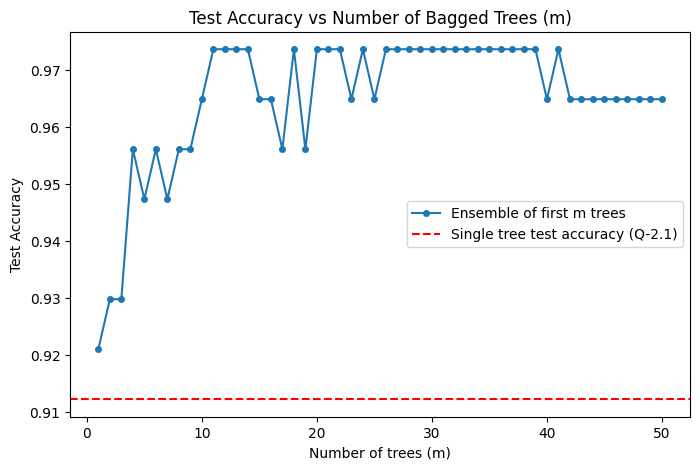

In [24]:
m_values = np.arange(1, T + 1)
acc_by_m = []

for m in m_values:
    pred_m = (tree_preds[:m].mean(axis=0) >= 0.5).astype(int)
    acc_by_m.append(accuracy_score(y_test, pred_m))

acc_by_m = np.array(acc_by_m)

plt.figure(figsize=(8, 5))

plt.plot(
    m_values,
    acc_by_m,
    marker="o",
    markersize=4,
    label="Ensemble of first m trees"
)

plt.axhline(
    y=tree_test_acc,
    linestyle="--",
    color="red",
    label="Single tree test accuracy (Q-2.1)"
)

plt.title("Test Accuracy vs Number of Bagged Trees (m)")
plt.xlabel("Number of trees (m)")
plt.ylabel("Test Accuracy")
plt.legend()
plt.show()

In [25]:
print("Test accuracy at selected values of m:")
for m in [1, 5, 10, 20, 30, 40, 50]:
    print(f"m = {m:2d}: {acc_by_m[m - 1]:.4f}")

print("\nMinimum accuracy for m >= 20:", acc_by_m[19:].min())
print("Maximum accuracy for m >= 20:", acc_by_m[19:].max())

Test accuracy at selected values of m:
m =  1: 0.9211
m =  5: 0.9474
m = 10: 0.9649
m = 20: 0.9737
m = 30: 0.9737
m = 40: 0.9649
m = 50: 0.9649

Minimum accuracy for m >= 20: 0.9649122807017544
Maximum accuracy for m >= 20: 0.9736842105263158


### 2.2 Interpretation

On average about 63.25% of the training rows appear at least once in a bootstrap sample (the simulated value 0.6325 matches the theoretical 1 - (1 - 1/n)^n = 0.6325), so about 36.7% of the rows are left out-of-bag for each tree. Voting reduces variance because every tree is trained on a different bootstrap sample, so the trees make different, only partly correlated mistakes, and the majority vote averages these out instead of repeating one tree's quirks. The 50-tree vote reaches 96.5% test accuracy compared with 91.2% for the single tree. The curve rises quickly from 92.1% at m = 1 to 96.5% by m = 10, then stays within a narrow band of 96.5% to 97.4% for m ≥ 20 (and is steady at 96.5% for m ≥ 42), so it levels off rather than keeping on improving; the small ups and downs are changes of a single test row (1 row = 0.9 percentage points).

____

## 2.3 Bagging with scikit-learn and the OOB Score

In [26]:
# Q-2.3

import warnings

n_estimators_list = [10, 25, 50, 100, 200, 300]

bag_n = []
bag_train_acc = []
bag_oob_acc = []
bag_test_acc = []

for n_est in n_estimators_list:
    bag = BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=n_est,
        oob_score=True,
        random_state=42
    )

    # for very small n_estimators some rows have no OOB prediction; the warning is expected
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="Some inputs do not have OOB scores")
        warnings.filterwarnings("ignore", message="invalid value encountered in divide")
        bag.fit(X_train, y_train)

    bag_n.append(n_est)
    bag_train_acc.append(accuracy_score(y_train, bag.predict(X_train)))
    bag_oob_acc.append(bag.oob_score_)
    bag_test_acc.append(accuracy_score(y_test, bag.predict(X_test)))

bagging_table = pd.DataFrame({
    "N_Estimators": bag_n,
    "Train_Acc": bag_train_acc,
    "OOB_Acc": bag_oob_acc,
    "Test_Acc": bag_test_acc
})

display(bagging_table)

,N_Estimators,Train_Acc,OOB_Acc,Test_Acc
0,10,0.995604,0.929670,0.929825
1,25,1.000000,0.956044,0.947368
2,50,1.000000,0.951648,0.938596
3,100,1.000000,0.956044,0.938596
4,200,1.000000,0.964835,0.947368
5,300,1.000000,0.964835,0.947368


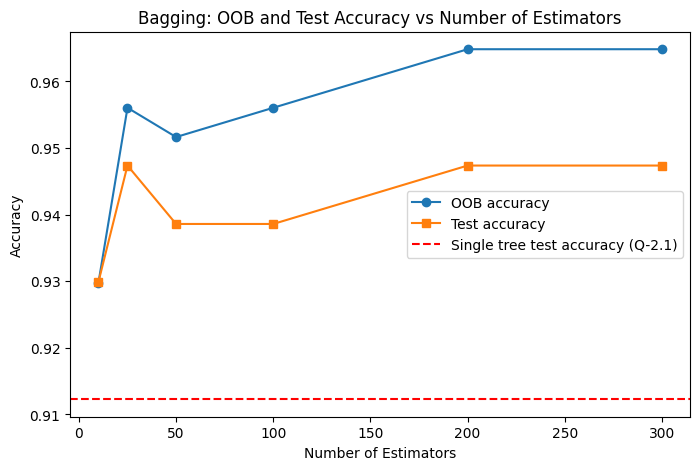

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(
    bagging_table["N_Estimators"],
    bagging_table["OOB_Acc"],
    marker="o",
    label="OOB accuracy"
)

plt.plot(
    bagging_table["N_Estimators"],
    bagging_table["Test_Acc"],
    marker="s",
    label="Test accuracy"
)

plt.axhline(
    y=tree_test_acc,
    linestyle="--",
    color="red",
    label="Single tree test accuracy (Q-2.1)"
)

plt.title("Bagging: OOB and Test Accuracy vs Number of Estimators")
plt.xlabel("Number of Estimators")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [28]:
# best_n is chosen using OOB accuracy only (ties -> smaller n_estimators)
max_oob = bagging_table["OOB_Acc"].max()
best_n = int(bagging_table.loc[bagging_table["OOB_Acc"] == max_oob, "N_Estimators"].min())

print("best_n:", best_n)
print("OOB accuracy at best_n:", max_oob)

best_n: 200
OOB accuracy at best_n: 0.9648351648351648


### 2.3 Interpretation

The bagged ensemble is clearly better than the single tree: with 200 trees the test accuracy is 94.7% compared with 91.2% for the single tree. The **OOB score** is the accuracy obtained by predicting each training row only with the trees whose bootstrap sample did not contain that row (about 37% of the trees), so it is a validation estimate computed from the training data alone; it needs no separate hold-out set, which is why it is a "free" estimate, and here it tracks the test accuracy closely (96.5% OOB against 94.7% test at 200 trees). Adding more trees did not make the model overfit: OOB accuracy rose from 93.0% at 10 trees to 96.5% at 200 trees and stayed there at 300, test accuracy rose from 93.0% to 94.7% and also stayed there, and the small dip at 50 trees is only a row or two. Bagging mainly reduces **variance**: each deep tree already has almost no bias (training accuracy of 100%) but high variance (91.2% test), and averaging keeps the low bias while stabilising the predictions. The best_n chosen from OOB accuracy alone is **200** (200 and 300 tie at 96.5%, so the smaller one is taken).

____

## 2.4 Random Forest and Feature Sub-sampling

In [29]:
# Q-2.4

max_features_options = [1, "log2", "sqrt", 0.5, None]

rf_labels = []
rf_n_features = []
rf_oob_acc = []
rf_test_acc = []

for mf in max_features_options:
    rf = RandomForestClassifier(
        n_estimators=200,
        max_features=mf,
        oob_score=True,
        random_state=42
    )
    rf.fit(X_train, y_train)

    rf_labels.append(str(mf))
    rf_n_features.append(rf.estimators_[0].max_features_)
    rf_oob_acc.append(rf.oob_score_)
    rf_test_acc.append(accuracy_score(y_test, rf.predict(X_test)))

rf_max_features_table = pd.DataFrame({
    "Max_Features": rf_labels,
    "N_Features_Per_Split": rf_n_features,
    "OOB_Acc": rf_oob_acc,
    "Test_Acc": rf_test_acc
})

display(rf_max_features_table)

,Max_Features,N_Features_Per_Split,OOB_Acc,Test_Acc
0,1,1,0.958242,0.956140
1,log2,4,0.956044,0.956140
2,sqrt,5,0.960440,0.956140
3,0.5,15,0.956044,0.956140
4,None,30,0.967033,0.947368


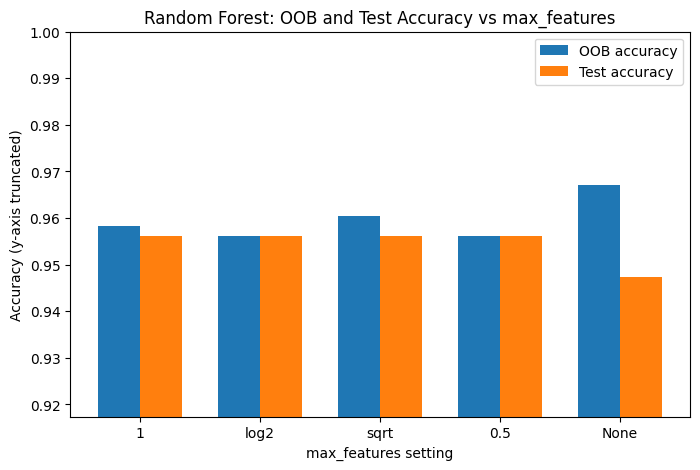

In [30]:
x_pos = np.arange(len(rf_max_features_table))
bar_width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x_pos - bar_width / 2,
    rf_max_features_table["OOB_Acc"],
    width=bar_width,
    label="OOB accuracy"
)

plt.bar(
    x_pos + bar_width / 2,
    rf_max_features_table["Test_Acc"],
    width=bar_width,
    label="Test accuracy"
)

lower_limit = min(rf_max_features_table["OOB_Acc"].min(), rf_max_features_table["Test_Acc"].min()) - 0.03

plt.ylim(lower_limit, 1.0)
plt.xticks(x_pos, rf_max_features_table["Max_Features"])

plt.title("Random Forest: OOB and Test Accuracy vs max_features")
plt.xlabel("max_features setting")
plt.ylabel("Accuracy (y-axis truncated)")
plt.legend()
plt.show()

In [31]:
# best_max_features is chosen using OOB accuracy only, among the four rows where max_features is not None
# (ties -> smaller N_Features_Per_Split)
candidates = rf_max_features_table.iloc[:-1]
best_idx = candidates.sort_values(
    by=["OOB_Acc", "N_Features_Per_Split"],
    ascending=[False, True]
).index[0]

best_max_features = max_features_options[best_idx]

print("best_max_features:", best_max_features)
print("Features per split:", rf_max_features_table.loc[best_idx, "N_Features_Per_Split"])
print("OOB accuracy:", rf_max_features_table.loc[best_idx, "OOB_Acc"])
print("\nReference (max_features=None, plain bagging) OOB accuracy:", rf_max_features_table.loc[len(rf_max_features_table) - 1, "OOB_Acc"])

best_max_features: sqrt
Features per split: 5
OOB accuracy: 0.9604395604395605

Reference (max_features=None, plain bagging) OOB accuracy: 0.967032967032967


### 2.4 Interpretation

Restricting max_features means each split can only choose from a random subset of the features, so the trees can no longer all put the same few dominant features at the top, which makes them less correlated than in plain bagging; averaging less correlated trees removes more variance. OOB_Acc went from 95.8% with max_features = 1 (1 feature per split) to 96.7% with max_features = None (30 features), a rise of about 0.9 percentage points (4 of 455 rows), and it is not monotonic (log2 and 0.5 are both 95.6%, sqrt is 96.0%), so all the differences are small. A very small max_features can hurt because a split may be forced to use a single, uninformative feature, which makes each individual tree weaker; a very large one can hurt because all trees look at the same strong features and become too similar, so averaging them removes little variance. The effect is weak here, probably because many of the 30 features are strongly informative, and among the four restricted settings OOB accuracy selects **sqrt** (5 features per split) as best_max_features.

____

## 2.5 Final Model and Feature Importance

In [32]:
# Q-2.5

final_rf = RandomForestClassifier(
    n_estimators=best_n,
    max_features=best_max_features,
    oob_score=True,
    random_state=42
)
final_rf.fit(X_train, y_train)

final_oob_acc = final_rf.oob_score_
final_test_pred_rf = final_rf.predict(X_test)
final_test_acc = accuracy_score(y_test, final_test_pred_rf)
cm = confusion_matrix(y_test, final_test_pred_rf)

print("Final Random Forest")
print("n_estimators:", best_n)
print("max_features:", best_max_features)
print("OOB accuracy:", final_oob_acc)
print("Test accuracy:", final_test_acc)

print("\nConfusion matrix (rows = true class, columns = predicted class):")
print(cm)

display(pd.DataFrame(
    cm,
    index=["True 0 (malignant)", "True 1 (benign)"],
    columns=["Pred 0 (malignant)", "Pred 1 (benign)"]
))

Final Random Forest
n_estimators: 200
max_features: sqrt
OOB accuracy: 0.9604395604395605
Test accuracy: 0.956140350877193

Confusion matrix (rows = true class, columns = predicted class):
[[39  3]
 [ 2 70]]


,Pred 0 (malignant),Pred 1 (benign)
True 0 (malignant),39,3
True 1 (benign),2,70


Top 10 feature importances:
worst perimeter         0.133100
worst area              0.128052
worst concave points    0.108107
mean concave points     0.094414
worst radius            0.090639
mean radius             0.058662
mean perimeter          0.055242
mean area               0.049938
mean concavity          0.046207
worst concavity         0.035357
dtype: float64


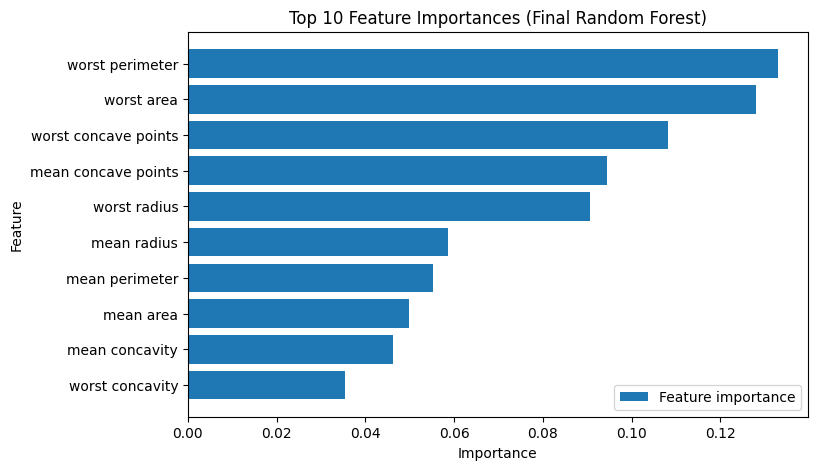

In [33]:
importances = pd.Series(final_rf.feature_importances_, index=X_train.columns)
top10 = importances.nlargest(10)

print("Top 10 feature importances:")
print(top10)

plt.figure(figsize=(8, 5))

# reversed so the most important feature appears at the top of the chart
plt.barh(top10.index[::-1], top10.values[::-1], label="Feature importance")

plt.title("Top 10 Feature Importances (Final Random Forest)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.legend()
plt.show()

In [34]:
bagging_test_acc = bagging_table.loc[bagging_table["N_Estimators"] == best_n, "Test_Acc"].iloc[0]

final_comparison = pd.DataFrame({
    "Model": ["Single Decision Tree", "Bagging", "Random Forest"],
    "Test_Accuracy": [tree_test_acc, bagging_test_acc, final_test_acc]
})

display(final_comparison)

,Model,Test_Accuracy
0,Single Decision Tree,0.912281
1,Bagging,0.947368
2,Random Forest,0.956140


### 2.5 Interpretation

The final Random Forest (200 trees, max_features = sqrt) has an OOB accuracy of 96.0% and a test accuracy of 95.6%, so the OOB estimate computed from the training data alone predicted the test performance well. The confusion matrix shows 5 mistakes out of 114 test cases: 3 malignant tumours predicted as benign and 2 benign tumours predicted as malignant, and the first kind of error is the more serious one in a screening setting. The importance chart is led by **worst perimeter** (0.133) and **worst area** (0.128), followed by worst concave points, mean concave points and worst radius, so tumour size and the concavity of the contour drive most of the decisions. Several of these features (radius, perimeter, area) are strongly correlated, so their importance is shared between them.

____

## Part 2 Final Report

In [35]:
display(final_comparison)

,Model,Test_Accuracy
0,Single Decision Tree,0.912281
1,Bagging,0.947368
2,Random Forest,0.956140


The single decision tree scored 91.2% test accuracy, bagging with 200 trees scored 94.7% and the final Random Forest scored 95.6% (final_comparison), so averaging many trees clearly beat one tree, while the step from bagging to the forest is only one test row. Bootstrap sampling gives every tree a different training set (about 63% distinct rows), so the trees differ and their votes cancel errors; the roughly 37% of rows left out gave the OOB score, which let me choose best_n = 200 and best_max_features = sqrt without touching the test set. Restricting the features at each split decorrelates the trees, although the OOB differences between settings were small (95.6% to 96.7%). The final test accuracy (95.6%) is close to its OOB estimate (96.0%), which supports OOB as a reliable guide. Worst perimeter and worst area mattered most. One drawback is that a forest of 200 trees is harder to interpret and more expensive to train and run than a single tree whose rules can be read directly.